# Validating the IID Assumption
Our models treat every row (one route in one week) as a separate, unrelated data point, and we split the data **randomly** instead of by time. That is only valid if the rows are **IID**:
- **Independent:** one row tells you nothing about another row
- **Identically distributed:** the rows all come from the same conditions

This notebook checks both, using `data/preprocessed/supply_chain_disruption.csv` from 01. No model is chosen or tuned here.

Checks:
1. Is a route independent of its own past weeks?
2. Are routes independent of each other in the same week?
3. Do the conditions stay the same over the years?
4. Does a random split give the same scores as a time-series split?

## 1. Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, f1_score
from sklearn.model_selection import StratifiedKFold

df = pd.read_csv("../data/preprocessed/supply_chain_disruption.csv")
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df = df.sort_values(["route_id", "date"]).reset_index(drop=True)
df["disrupted"] = (df["route_status"] == "Disrupted").astype(int)

# 01 found the last 30 weeks look different, so checks 1 and 2 use the weeks before them (check 3 covers the change)
shift_start = pd.Timestamp("2026-06-07")
stable_df = df[df["date"] < shift_start]

target_columns = ["shipping_delay_days", "disrupted"]
core_features = ["geopolitical_risk_score", "port_congestion_index", "weather_disruption_score"]
check_columns = target_columns + core_features

print("Rows:", len(df), "| routes:", df["route_id"].nunique(), "| weeks:", df["date"].nunique())

Rows: 31300 | routes: 50 | weeks: 626


## 2. Is a Route Independent of Its Own Past?
**Autocorrelation** compares each week's value with the same route's value 1, 4, 12 or 52 weeks earlier. About **0** means past weeks say nothing about this week. Close to **1** means the value carries over from week to week.

The table shows the average over the 50 routes.

In [2]:
lags = [1, 4, 12, 52]
autocorrelation = pd.DataFrame({
    f"{lag} week{'s' if lag > 1 else ''} earlier": {column: stable_df.groupby("route_id")[column].apply(lambda s: s.autocorr(lag)).mean()
                             for column in check_columns}
    for lag in lags
}).round(3)
autocorrelation

,1 week earlier,4 weeks earlier,12 weeks earlier,52 weeks earlier
shipping_delay_days,0.003,-0.001,0.003,-0.010
disrupted,0.000,-0.000,-0.010,-0.007
geopolitical_risk_score,-0.001,-0.006,-0.001,0.001
port_congestion_index,0.000,0.006,-0.009,-0.012
weather_disruption_score,-0.003,-0.009,-0.003,0.008


**Reading the table:** each value is the correlation of one column **with itself**, on the same route, some weeks earlier. It is not a correlation with the label (status).

For example, 0.003 for `shipping_delay_days` at "1 week earlier" means a route's delay this week has almost no relation to its delay last week. The calculation runs for each of the 50 routes separately, and the table shows the average.

**What we want:** values close to **0**. IID means a row tells you nothing about other rows, including the same route's earlier weeks. A value close to 1 would mean the rows are linked.

In [3]:
# Does a disruption make another disruption more likely the following week?
previous_week = stable_df.groupby("route_id")["disrupted"].shift(1)
print(f"Disrupted rate overall:                 {stable_df['disrupted'].mean():.2%}")
print(f"Disrupted rate after a Disrupted week:  {stable_df.loc[previous_week == 1, 'disrupted'].mean():.2%}")

Disrupted rate overall:                 2.41%
Disrupted rate after a Disrupted week:  2.65%


- **The delay, the Disrupted status and the 3 core features are independent over time.** Every value is about 0, even one year back (52 weeks), so there is also no seasonal pattern.
- **Disruptions don't come in streaks.** A route is about as likely to be disrupted after a Disrupted week as at any other time.

## 3. Are Routes Independent of Each Other?
If something hit many routes in the same week, the routes would move together. Two checks:
- **Correlation between routes:** the average correlation between every pair of routes, week by week. About 0 means routes don't move together.
- **Disruptions per week:** if routes are independent, the number of disruptions per week varies about as much as its average (variance ≈ mean). If routes failed together, the variance would be much larger.

### How the Route Pairs Are Formed
1. **Reshape:** one row per week, one column per route. Each cell is that route's value in that week.
2. **Pair up routes:** take two route columns, e.g. R1 and R2. They line up week by week, so their correlation measures whether R1 and R2 go up and down **in the same weeks**.
3. **Every pair:** 50 routes give 50 x 49 / 2 = **1,225 pairs**. `corr()` computes all of them at once as a 50 x 50 table.
4. **Average:** the table lists each pair twice (R1-R2 and R2-R1) plus each route with itself (always 1), so only the cells above the diagonal are kept, then averaged.

The cell below shows step 1 for `shipping_delay_days` (how many days late each route's shipments were), first 5 weeks, routes R1 to R5:

In [4]:
# Step 1: one row per week, one column per route
example_table = stable_df.pivot(index="date", columns="route_id", values="shipping_delay_days")
example_table[["R1", "R2", "R3", "R4", "R5"]].head()

route_id,R1,R2,R3,R4,R5
date,,,,,
2015-01-04,7.55,0.00,5.65,6.32,2.28
2015-01-11,9.33,4.03,9.29,7.36,9.81
2015-01-18,3.67,9.87,8.49,5.32,6.17
2015-01-25,9.22,3.92,4.98,6.16,6.66
2015-02-01,6.36,6.66,6.00,8.39,5.02


**Reading the table:** each row is a week, each column is a route, and each cell is that route's delay in days that week. For example, R1 was 7.55 days late in the week of 2015-01-04, while R2 was on time (0.00).

The delay also sets the status (02_1): under 5 days is Normal, 5 to 12 is Delayed, 12 or more is Disrupted. So R1 was Delayed that week and R2 was Normal.

**What we look for:** if routes depended on each other, a long delay on one route would come with long delays on others in the same week. Here they don't line up: R1's longest delays (9.33, 9.22) fall in weeks where R2's are short (4.03, 3.92). The next cell measures this for R1 and R2.

In [5]:
# Step 2 for one pair: do R1 and R2 have high delays in the same weeks?
print("Correlation of shipping_delay_days, R1 vs R2:", round(example_table["R1"].corr(example_table["R2"]), 3))

Correlation of shipping_delay_days, R1 vs R2: 0.028


In [6]:
def correlation_between_routes(column):
    """Average correlation between every pair of routes, for one column."""
    # Step 1: one row per week, one column per route (596 weeks x 50 routes before the shift)
    by_route = stable_df.pivot(index="date", columns="route_id", values=column)

    # Step 2-3: correlation of every route column with every other route column (50 x 50 table)
    correlations = by_route.corr().to_numpy()

    # Step 4: keep each pair once (above the diagonal: 1,225 pairs), then average
    pairs = correlations[np.triu_indices_from(correlations, k=1)]
    return pairs.mean()

route_correlation = pd.Series({column: correlation_between_routes(column) for column in check_columns},
                              name="average correlation between routes").round(3).to_frame()
route_correlation

,average correlation between routes
shipping_delay_days,-0.001
disrupted,-0.000
geopolitical_risk_score,-0.000
port_congestion_index,-0.001
weather_disruption_score,0.002


In [7]:
disruptions_per_week = stable_df.groupby("date")["disrupted"].sum()
print(f"Disruptions per week: mean {disruptions_per_week.mean():.2f}, variance {disruptions_per_week.var():.2f}")

Disruptions per week: mean 1.20, variance 1.16


- **Routes are independent of each other** for the delay, the status and the 3 core features (correlation about 0).
- **Disruptions don't cluster in the same week:** the variance is about equal to the mean.

## 4. Do the Conditions Stay the Same Over Time?
"Identically distributed" means the data looks the same in every period. The table shows each year's Disrupted rate and average values.

In [8]:
by_year = df.groupby(df["date"].dt.year).agg(
    disrupted_percent=("disrupted", lambda s: s.mean() * 100),
    delay_days=("shipping_delay_days", "mean"),
    geopolitical_risk=("geopolitical_risk_score", "mean"),
    port_congestion=("port_congestion_index", "mean"),
    weather=("weather_disruption_score", "mean"),
).rename_axis("year")
by_year.round(1)

,disrupted_percent,delay_days,geopolitical_risk,port_congestion,weather
year,,,,,
2015,2.8,6.4,50.1,50.3,50.8
2016,2.5,6.3,49.0,49.6,51.2
2017,2.3,6.3,50.7,49.5,51.4
2018,2.7,6.3,49.5,49.9,50.3
2019,2.6,6.2,49.8,49.8,50.3
2020,2.5,6.3,49.8,49.3,50.5
2021,2.4,6.3,50.2,49.9,51.0
2022,2.3,6.3,48.8,49.9,50.4
2023,2.3,6.2,49.7,50.2,49.8


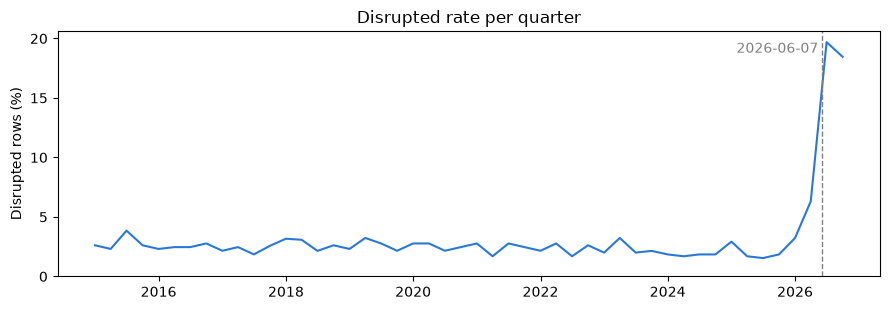

In [9]:
# The same view by quarter, to see when the change happens
by_quarter = df.groupby(df["date"].dt.to_period("Q"))["disrupted"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(by_quarter.index.to_timestamp(), by_quarter.values, color="#2a78d6")
ax.axvline(shift_start, color="gray", linestyle="--", linewidth=1)
ax.text(shift_start, by_quarter.max(), "2026-06-07 ", color="gray", ha="right", va="top")
ax.set_ylabel("Disrupted rows (%)")
ax.set_title("Disrupted rate per quarter")
ax.set_ylim(0)
plt.tight_layout()
plt.show()

In [10]:
# The same columns before and from 2026-06-07 (the last 30 weeks)
period = np.where(df["date"] < shift_start, "before 2026-06-07", "from 2026-06-07 (last 30 weeks)")
df.groupby(period).agg(
    weeks=("date", "nunique"),
    disrupted_percent=("disrupted", lambda s: s.mean() * 100),
    delay_days=("shipping_delay_days", "mean"),
    geopolitical_risk=("geopolitical_risk_score", "mean"),
    port_congestion=("port_congestion_index", "mean"),
    weather=("weather_disruption_score", "mean"),
).round(1)

,weeks,disrupted_percent,delay_days,geopolitical_risk,port_congestion,weather
before 2026-06-07,596,2.4,6.3,49.9,49.7,50.5
from 2026-06-07 (last 30 weeks),30,18.7,8.4,71.3,49.1,50.8


- **2015 to mid-2026 is stable:** the Disrupted rate stays between about 2% and 3% a year, and the averages barely move.
- **The last 30 weeks (from 2026-06-07) are different:** the Disrupted rate rises to about 19% and geopolitical risk jumps from about 50 to about 71. 01 found the commodity values change in exactly these weeks.

So the data is identically distributed **except for the last 30 weeks**. Because our split is random, those weeks are in both the training and the test set, so the model sees both conditions. Scores should be reported for the two periods separately as well as together.

## 5. Does a Random Split Change the Scores?
The practical test. If rows were **not** independent, a random split would let the model learn from weeks right next to the ones it is tested on, and it would score better than it deserves.

Two ways of testing are compared on the stable period, both scored on the **same rows** (2021 to 2025):
- **Random folds:** stratified 5-fold cross-validation, as in our other notebooks
- **Time-series split:** train only on earlier years, test on the next year (2021, then 2022, ..., 2025). The model never sees the future

The model is a simple untuned gradient-boosted tree model with class weights, using the 7 features from `model_ready.csv` (training rows only).

In [11]:
model_ready_df = pd.read_csv("../data/preprocessed/model_ready.csv")
model_ready_df["date"] = pd.to_datetime(model_ready_df["date"], format="%m/%d/%Y")

train_df = model_ready_df[(model_ready_df["split"] == "train") & (model_ready_df["date"] < shift_start)].reset_index(drop=True)
feature_columns = [c for c in train_df.columns if c not in ["date", "route_id", "split", "route_status"]]
y = train_df["route_status"].map({"Normal": 0, "Delayed": 1, "Disrupted": 2}).to_numpy()
year = train_df["date"].dt.year.to_numpy()
rows = np.arange(len(train_df))
test_years = [2021, 2022, 2023, 2024, 2025]

def fit_and_score(train_rows, test_rows):
    """Train on train_rows, return macro-F1 and Disrupted PR-AUC on test_rows."""
    model = HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.05, max_iter=300, random_state=42)
    model.fit(train_df.iloc[train_rows][feature_columns], y[train_rows])
    probabilities = model.predict_proba(train_df.iloc[test_rows][feature_columns])
    return {"macro_f1": f1_score(y[test_rows], probabilities.argmax(axis=1), average="macro"),
            "disrupted_pr_auc": average_precision_score(y[test_rows] == 2, probabilities[:, 2])}

# Random folds: score only the held-out rows from 2021 to 2025
random_scores = pd.DataFrame([
    fit_and_score(train_rows, test_rows[np.isin(year[test_rows], test_years)])
    for train_rows, test_rows in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(train_df, y)
])

# Time-series split: train on all earlier years, test on one year
time_scores = pd.DataFrame([fit_and_score(rows[year < test_year], rows[year == test_year]) for test_year in test_years])

# One row per method, each score shown as mean ± std over the 5 test sets
def mean_and_std(scores):
    return {metric: f"{scores[metric].mean():.3f} ± {scores[metric].std():.3f}" for metric in scores.columns}

pd.DataFrame({"Random folds": mean_and_std(random_scores), "Time-series split": mean_and_std(time_scores)}).T.rename(
    columns={"macro_f1": "Macro F1", "disrupted_pr_auc": "Disrupted PR-AUC"})

,Macro F1,Disrupted PR-AUC
Random folds,0.513 ± 0.010,0.186 ± 0.041
Time-series split,0.523 ± 0.017,0.196 ± 0.043


**How the rounds work:**

| Round | Random folds | Time-series split |
|---|---|---|
| 1 | Train on folds 2–5, test on fold 1 | Train on 2015–2020, test on 2021 |
| 2 | Train on folds 1, 3–5, test on fold 2 | Train on 2015–2021, test on 2022 |
| 3 | Train on folds 1–2, 4–5, test on fold 3 | Train on 2015–2022, test on 2023 |
| 4 | Train on folds 1–3, 5, test on fold 4 | Train on 2015–2023, test on 2024 |
| 5 | Train on folds 1–4, test on fold 5 | Train on 2015–2024, test on 2025 |

- **Random folds:** the rows (2015 to mid-2026) are shuffled into 5 folds with the same mix of statuses. Training uses rows from every year, and only the test fold's 2021–2025 rows are scored.
- **Time-series split:** training only uses years before the test year, so the model never sees the future.

In [12]:
# Every round behind the averages above (5 rounds per method)
names = {"macro_f1": "Macro F1", "disrupted_pr_auc": "Disrupted PR-AUC"}
all_rounds = pd.concat({
    "Random folds": random_scores.rename(columns=names),
    "Time-series split": time_scores.rename(columns=names).assign(**{"Test year": test_years})[["Test year", *names.values()]],
}, axis=1)
all_rounds.index = [f"Round {i}" for i in range(1, len(all_rounds) + 1)]
all_rounds.round(3)

Random folds                  Time-series split           \
            Macro F1 Disrupted PR-AUC         Test year Macro F1   
Round 1        0.495            0.134              2021    0.538   
Round 2        0.518            0.249              2022    0.541   
Round 3        0.521            0.183              2023    0.517   
Round 4        0.518            0.184              2024    0.498   
Round 5        0.513            0.180              2025    0.520   

                          
        Disrupted PR-AUC  
Round 1            0.243  
Round 2            0.238  
Round 3            0.176  
Round 4            0.177  
Round 5            0.143

**The scores are the same** (the difference is smaller than the spread between folds). Testing on future years is not harder than testing on random rows, so the random split does not give the model an unfair advantage.

## 6. Conclusion

| Check | Result |
|---|---|
| Independent over time | **Yes.** A route's past weeks say nothing about this week (autocorrelation between -0.012 and 0.008, even 52 weeks back) |
| Independent across routes | **Yes.** Routes don't move together in the same week (correlation between -0.001 and 0.002) |
| Identically distributed | **Yes for 2015 to mid-2026** (2–3% disrupted each year). **No for the last 30 weeks** (about 19% disrupted) |
| Random split vs. time-series split | **Same scores.** Macro F1 0.513 vs. 0.523, Disrupted PR-AUC 0.186 vs. 0.196 |

**Our approach is valid:** the rows behave as independent data points, so a random stratified split and stratified K-fold are appropriate.